# Pregunta 2 - Grupo 7
#### Integrantes:
- Agustín Pérez
- Vicente Pardo
- Cristóbal Robinson
- Sofía Solorza

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Inciso A
$\sigma(t) = \frac{1}{1+e^{-t}}$ Calculamos la derivada de $\sigma$ con la derivada por diferencias centradas $\sigma'(t)=\frac{\sigma(t+h)-\sigma(t-h)}{2h}$


La comparamos con $\sigma(t)\big(1-\sigma(t)\big)$ en 20 valores de $t$ elegidos al azar


In [2]:
np.random.seed(0)
t = np.sort(np.random.uniform(-5, 5, 20))
h = 10**-5 # tiende a cero
sigma1 = 1 /(1 + np.exp(-(t + h))) 
sigma2 = 1 /(1 + np.exp(-(t - h)))
derivada = (sigma1 - sigma2) /(2*h) 
sigma = 1 /(1 + np.exp(-t))
formula = sigma * (1 - sigma) 
for i in range(len(derivada)):
    print("derivada:", derivada[i], "formula:", formula[i])

derivada: 0.008113354650878674 formula: 0.008113354650993875
derivada: 0.013341538785544003 formula: 0.013341538785816495
derivada: 0.01559729464542525 formula: 0.01559729464572147
derivada: 0.1811745643773288 formula: 0.18117456437619062
derivada: 0.21683859494359134 formula: 0.21683859494578764
derivada: 0.22715162513731177 formula: 0.22715162514236292
derivada: 0.24485353601333412 formula: 0.24485353601631113
derivada: 0.23782034920261094 formula: 0.23782034920887632
derivada: 0.2356798098346324 formula: 0.23567980984056694
derivada: 0.22315706195152882 formula: 0.2231570619509202
derivada: 0.19408813732857408 formula: 0.19408813733171157
derivada: 0.15304830582874018 formula: 0.1530483058283555
derivada: 0.09330626091763604 formula: 0.09330626091624622
derivada: 0.05492619649660745 formula: 0.054926196496213636
derivada: 0.048674926861336225 formula: 0.04867492686057359
derivada: 0.03348035236272473 formula: 0.033480352357274167
derivada: 0.023542186122771366 formula: 0.02354218613

La derivada y la fórmula son iguales en todos los puntos, entonces se satisface $\sigma'(t)=\sigma(t)\big(1-\sigma(t)\big)$. Tambien los valores de la derivada son positivos, teniendo $0<\sigma'(t)<=1/4$

Para el máximo derivamos otra vez y vemos su signo

In [3]:
derivada1 = sigma1 * (1 - sigma1) # metodo probado
derivada2 = sigma2 * (1 - sigma2)
segunda = (derivada1 - derivada2) / (2*h)
for i in range(len(segunda)):
    print("t:", np.round(t[i], 4), "segunda derivada:", np.round(segunda[i], 6))

t: -4.7978 segunda derivada: 0.007981
t: -4.2896 segunda derivada: 0.012981
t: -4.1287 segunda derivada: 0.015103
t: -1.1656 segunda derivada: 0.095061
t: -0.7635 segunda derivada: 0.078974
t: -0.6241 segunda derivada: 0.068671
t: 0.2889 segunda derivada: -0.035131
t: 0.4488 segunda derivada: -0.052492
t: 0.4881 segunda derivada: -0.056406
t: 0.6804 segunda derivada: -0.073123
t: 1.0276 segunda derivada: -0.091787
t: 1.4589 segunda derivada: -0.09531
t: 2.1519 segunda derivada: -0.07387
t: 2.7816 segunda derivada: -0.048519
t: 2.9173 segunda derivada: -0.04368
t: 3.3262 segunda derivada: -0.031158
t: 3.7001 segunda derivada: -0.022406
t: 3.9177 segunda derivada: -0.018373
t: 4.256 segunda derivada: -0.0134
t: 4.6366 segunda derivada: -0.009323


La segunda derivada es positiva en los t negativos, por lo que crece y negativa en los positivos, decreciendo, entonces cambia de signo en t = 0 y ahi $\sigma'$ alcanza su máximo


Evaluamos la derivada en ese punto

In [4]:
t0 = 0
sigma0 = 1 / (1 + np.exp(-t0))
derivada0 = sigma0 * (1 - sigma0)
print(derivada0)

0.25


La derivada alcanza su máximo en $t=0$, donde vale 1/4

## Inciso B
Queremos calcular el gradiente en un punto cualquiera $\theta=(a_1,b_1,a_2,b_2,v,c)$ elegido al azar en $[-1,1]$ para un dato cualquiera $(x_i,y_i)$

In [5]:
np.random.seed(0)
theta = np.random.uniform(-1, 1, 6) # armamos theta
a1, b1, a2, b2, v, c = theta
xi = np.random.uniform(-1, 1) # entrada
yi = np.random.uniform(-1, 1)
print(theta)
print(xi, yi) # dato

[ 0.09762701  0.43037873  0.20552675  0.08976637 -0.1526904   0.29178823]
-0.12482557747461498 0.7835460015641595


Pasamos el dato capa por capa

$z_{1,i}=a_1x_i+b_1,\quad h_{1,i}=\sigma(z_{1,i}),\quad z_{2,i}=a_2h_{1,i}+b_2,\quad h_{2,i}=\sigma(z_{2,i}),\quad \hat y_i=c+v\,h_{2,i},\quad e_i=\hat y_i-y_i,\quad L_i=\tfrac12e_i^2$

In [6]:
z1 = a1*xi + b1 # capa 1
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2 # capa 2
h2 = 1 / (1 + np.exp(-z2))
ygorro = c + v*h2# capa salida
e = ygorro - yi
L = e**2 / 2

print("z1:", z1, "  h1:", h1, "z2:", z2, "  h2:", h2, "ygorro:", ygorro, "  e:", e, "  L:", L)

z1: 0.41819238511226353   h1: 0.6030506226898621 z2: 0.21370940185322834   h2: 0.5532249316963992 ygorro: 0.2073160892911476   e: -0.5762299122730119   L: 0.1660204558990815


Usamos la regla de la cadena y definicion de la derivada para cada capa y las multiplicamos. Como señala el enunciado, muchos pasos se repiten, entonces cada uno se calcula una sola vez usando df/dx = (f(…, x + h, …) − f(…, x − h, …)) /(2h), elegimos un h pequeño y fijo. Partimos por la perdida $L_i=\tfrac12e_i^2$ y el error $e_i=\hat y_i-y_i$

In [7]:
h = 10**-5
# respecto a todas las variables que salen en su capa
derivadaLi_de = ((e + h)**2 /2 - (e - h)**2 /2) /(2*h) 
derivadaError_dy = ((ygorro + h - yi) -(ygorro - h - yi)) /(2*h)
print(derivadaLi_de)
print(derivadaError_dy)

-0.5762299122705206
1.000000000001


Capa de salida $\hat y_i=c+v\,h_{2,i}$

In [8]:
derivadaY_dc  = ((c + h + v*h2) -(c - h + v*h2))/ (2*h)
derivadaY_dv  = ((c + (v + h)*h2) -(c + (v - h)*h2))/(2*h)
derivadaY_dh2 = ((c + v*(h2 + h)) -(c + v*(h2 - h))) /(2*h)
print(derivadaY_dc)
print(derivadaY_dv)
print(derivadaY_dh2)

1.000000000001
0.5532249316958504
-0.1526904013213204


Capa oculta 2 $h_{2,i}=\sigma(z_{2,i}) = \sigma(a_2h_{1,i}+b_2)$

In [9]:
derivadaH2_dz2 = (1 /(1 + np.exp(-(z2 + h))) -1 /(1 + np.exp(-(z2 - h))))/ (2*h)
derivadaZ2_db2 = ((a2*h1 + b2 + h) - (a2*h1 + b2 - h))/ (2*h)
derivadaZ2_da2 = (((a2 + h)*h1 + b2) -((a2 - h)*h1 + b2))/ (2*h)
derivadaZ2_dh1 = ((a2*(h1 + h) + b2) - (a2*(h1 - h) + b2))/ (2*h)
print(derivadaH2_dz2)
print(derivadaZ2_db2)
print(derivadaZ2_da2)
print(derivadaZ2_dh1)

0.24716710664285377
1.000000000001
0.6030506226897825
0.20552675214224878


Capa oculta 1 $h_{1,i}=\sigma(z_{1,i})=\sigma(a_1x_i+b_1)$

In [10]:
derivadaH1_dz1 = (1 / (1 + np.exp(-(z1 + h))) - 1 / (1 + np.exp(-(z1 - h))))/(2*h)
derivadaZ1_db1 = ((a1*xi + b1 + h) - (a1*xi + b1 - h)) / (2*h)
derivadaZ1_da1 = (((a1 + h)*xi + b1) - ((a1 - h)*xi + b1)) / (2*h)
print(derivadaH1_dz1)
print(derivadaZ1_db1)
print(derivadaZ1_da1)

0.2393805691613959
1.000000000001
-0.1248255774743967


- salida, $\;c \to \hat y_i \to e_i \to L_i$  y $\;v \to \hat y_i \to e_i \to L_i$
- capa oculta 2, $\;b_2 \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$ y $\;a_2 \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$
- capa oculta 1, $\;b_1 \to z_{1,i} \to h_{1,i} \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$  y $\;a_1 \to z_{1,i} \to h_{1,i} \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$ 

In [11]:
derivadaLi_dc = derivadaLi_de * derivadaError_dy * derivadaY_dc # salida
derivadaLi_dv = derivadaLi_de * derivadaError_dy * derivadaY_dv
print("derivadaLi dc =", derivadaLi_dc, "derivadaLi dv =", derivadaLi_dv)

derivadaLi_db2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_db2 # capa 2
derivadaLi_da2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_da2
print("derivadaLi db2 =", derivadaLi_db2, "derivadaLi da2 =", derivadaLi_da2)

derivadaLi_db1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_db1 #capa 1
derivadaLi_da1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_da1
print("derivadaLi db1 =", derivadaLi_db1, "derivadaLi da1 =", derivadaLi_da1)



derivadaLi dc = -0.5762299122716732 derivadaLi dv = -0.31878475385728344
derivadaLi db2 = 0.021746942650486285 derivadaLi da2 = 0.013114507306961627
derivadaLi db1 = 0.0010699302433212737 derivadaLi da1 = -0.00013355466047976618


Juntamos las seis derivadas en el gradiente, en el orden $\theta=(a_1,b_1,a_2,b_2,v,c)$

In [12]:
gradiente = np.array([derivadaLi_da1, derivadaLi_db1, derivadaLi_da2, derivadaLi_db2, derivadaLi_dv, derivadaLi_dc])
print(gradiente)

[-1.33554660e-04  1.06993024e-03  1.31145073e-02  2.17469427e-02
 -3.18784754e-01 -5.76229912e-01]


Obtenemos el gradiente de la pérdida $L_i$ de un dato

## Inciso C

Cargamos los 200 pares $(x_i, y_i)$.


In [13]:
df = pd.read_csv("datos/datos_P2.csv")
x = df["x"].to_numpy()
y = df["y"].to_numpy()
N = len(x)
print("N =", N)
print("x[0:5] =", np.round(x[:5], 4))
print("y[0:5] =", np.round(y[:5], 4))

N = 200
x[0:5] = [-7.830e-02  5.541e-01  4.000e-04 -1.749e-01  5.690e-02]
y[0:5] = [0.9378 0.0584 0.7272 1.0506 0.5781]


Definimos $J(\theta)=\frac{1}{2N}\sum_{i=1}^{N} e_i^2$ con $e_i=\hat{y}_i - y_i$. Paso capa por capa $z_{1,i}=a_1 x_i + b_1$, $h_{1,i}=\sigma(z_{1,i})$, $z_{2,i}=a_2 h_{1,i} + b_2$, $h_{2,i}=\sigma(z_{2,i})$, $\hat{y}_i=c+v h_{2,i}$.


In [14]:
def J(theta):
    a1, b1, a2, b2, v, c = theta
    s = 0.0 # sumatoria e
    for i in range(N):
        z1 = a1*x[i] + b1
        h1 = 1 / (1 + np.exp(-z1))
        z2 = a2*h1 + b2
        h2 = 1 / (1 + np.exp(-z2))
        y_gorro = c + v*h2
        e = y_gorro - y[i]
        s += e**2 / 2
    return s / N

Definimos gradiente $\nabla_{\theta} J$ por regla de la cadena. Por (a) cada derivada se calculara con $\sigma'=\sigma(t)\big(1-\sigma(t)\big)$ donde hay una sigmoide, luego se promedia sobre los $N$ datos: $\frac{\partial J}{\partial \theta^{(j)}}=\frac{1}{N}\sum_{i=1}^{N}\frac{\partial L_i}{\partial \theta^{(j)}}$

$z_{1,i}=a_1x_i+b_1,\quad h_{1,i}=\sigma(z_{1,i}),\quad z_{2,i}=a_2h_{1,i}+b_2,\quad h_{2,i}=\sigma(z_{2,i}),\quad \hat y_i=c+v\,h_{2,i},\quad e_i=\hat y_i-y_i,\quad L_i=\tfrac12e_i^2$


In [15]:
def grad_J(theta):
    a1, b1, a2, b2, v, c = theta
    grad = np.zeros(6) # suma en 0 
    for i in range(N): 
        z1 = a1*x[i] + b1 # capas para xi,yi
        h1 = 1 / (1 + np.exp(-z1))
        z2 = a2*h1 + b2
        h2 = 1 / (1 + np.exp(-z2))
        y_gorro = c + v*h2
        e = y_gorro - y[i]
        derivadaLi_de = e
        derivadaError_dy = 1
        derivadaY_dc = 1
        derivadaY_dv = h2
        derivadaY_dh2 = v
        derivadaH2_dz2 = h2 * (1 - h2) # o'(z2)= oz2(1 - oz2) y oz2=h2
        derivadaZ2_db2 = 1 
        derivadaZ2_da2 = h1
        derivadaZ2_dh1 = a2
        derivadaH1_dz1 = h1 * (1 - h1)
        derivadaZ1_db1 = 1
        derivadaZ1_da1 = x[i]

        derivadaLi_dc = derivadaLi_de * derivadaError_dy * derivadaY_dc # salida
        derivadaLi_dv = derivadaLi_de * derivadaError_dy * derivadaY_dv
        derivadaLi_db2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_db2 # capa 2
        derivadaLi_da2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_da2
        derivadaLi_db1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_db1 #capa 1
        derivadaLi_da1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_da1
        grad[0] += derivadaLi_da1 
        grad[1] += derivadaLi_db1
        grad[2] += derivadaLi_da2
        grad[3] += derivadaLi_db2
        grad[4] += derivadaLi_dv
        grad[5] += derivadaLi_dc
    return grad / N

Inicializamos $\theta_0 \sim U[-1,1]$ con `np.random.seed(0)` y verificamos por diferencias centradas $D_j=\frac{J(\theta_0+h e_j)-J(\theta_0-h e_j)}{2h}$ con $h=10^{-5}$.


In [16]:
np.random.seed(0)
theta0 = np.random.uniform(-1, 1, 6)
print("theta0 =", np.round(theta0, 6))
print("J(theta0) =", J(theta0))
g0 = grad_J(theta0)
print("grad_J(theta0) =", np.round(g0, 6))

h = 10**-5
D = np.zeros(6)
for j in range(6):
    ej = np.zeros(6); ej[j] = 1 # vector canonico
    D[j] = (J(theta0 + h*ej) - J(theta0 - h*ej)) / (2*h) 
print("Dj =", np.round(D, 6))
print("error |grad-Dj| =", np.round(np.abs(g0 - D), 10)) # diferencia entre metodos
E = np.max(np.abs(g0 - D)) # mayor de las 6
print("E = max |grad-Dj| =", E)

theta0 = [ 0.097627  0.430379  0.205527  0.089766 -0.15269   0.291788]
J(theta0) = 0.603522343354513
grad_J(theta0) = [-0.000862  0.001382  0.016455  0.027827 -0.407364 -0.737138]
Dj = [-0.000862  0.001382  0.016455  0.027827 -0.407364 -0.737138]
error |grad-Dj| = [0. 0. 0. 0. 0. 0.]
E = max |grad-Dj| = 1.6643780104130812e-11


## Inciso D

Descenso $\theta_{k+1}=\theta_k - \alpha \nabla J(\theta_k)$ con paso fijo $\alpha=1$ partiendo del mismo $\theta_0$ de C, por $20000$ iteraciones.


In [17]:
alpha = 1.0
max_iter = 20000
theta = theta0.copy()
hist_J = np.zeros(max_iter +1) # historial de errores
hist_J[0] = J(theta0)

for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - alpha * g 
    hist_J[k+1] = J(theta)

print("theta0 =", np.round(theta0,6))
print("theta20000 =", np.round(theta,6))
print("J(theta0) =", J(theta0))
print("J(theta20000) =", hist_J[-1])
g_final = grad_J(theta) # theta20000
print("grad J(theta20000) =", g_final)
print("||grad J(theta20000)|| =", np.linalg.norm(g_final)) # norma

theta0 = [ 0.097627  0.430379  0.205527  0.089766 -0.15269   0.291788]
theta20000 = [-4.366759 -0.747365  3.555817 -1.627432  2.960878 -0.439813]
J(theta0) = 0.603522343354513
J(theta20000) = 0.001373561381571473
grad J(theta20000) = [-3.56918778e-06 -8.40488446e-07 -7.68943078e-06  4.46290586e-06
  3.92452023e-06 -2.41679108e-06]
||grad J(theta20000)|| = 1.0664573822465625e-05


Graficamos la evolución del error $J(\theta_k)$.


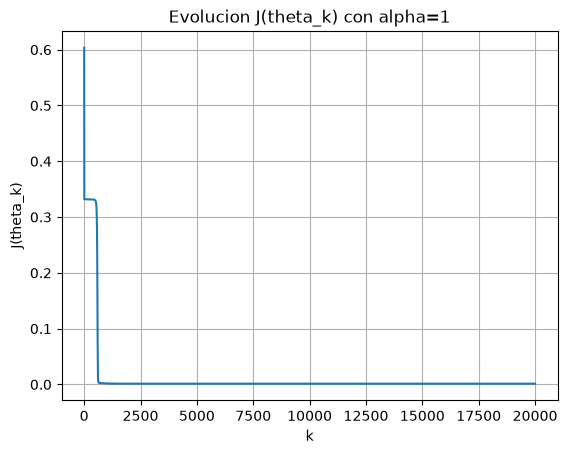

In [18]:
plt.figure()
plt.plot(hist_J)
plt.xlabel("k")
plt.ylabel("J(theta_k)")
plt.title("Evolucion J(theta_k) con alpha=1")
plt.grid(True)
plt.show()

Notamos una caída brusca del error antes de las primeras 2500 iteraciones, estas son las que más reducen el error. Luego casi no cambia

## Inciso E
Obtenemos los 6 parámetros finales de la red, $\theta_{20.000}=(a_1,b_1,a_2,b_2,v,c)$ y el valor de la pérdida

In [19]:
a1, b1, a2, b2, v, c = theta # entrenado
print("a1 =", a1, ",b1 =", b1, "a2 =", a2, "b2 =",b2, "v =", v,"c =", c)
print("perdida =", J(theta))

a1 = -4.3667589161405065 ,b1 = -0.7473648016695782 a2 = 3.55581651610429 b2 = -1.6274318159578447 v = 2.9608783081735455 c = -0.43981266252455875
perdida = 0.001373561381571473


Notamos de los parametros que multiplican que $a_1<0$, $a_2>0$ y $v>0$, por regla de signos la salida de la red decrece

Calculamos la salida de la red en cada uno de los 100 valores de x que creamos entre [-1, 1], capa por capa

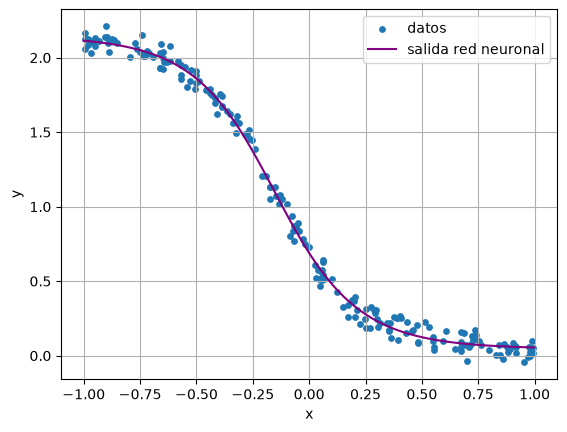

In [20]:
xcurva = np.linspace(-1, 1, 100)
z1 = a1*xcurva + b1 
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2 
h2 = 1 / (1 + np.exp(-z2))
ycurva = c + v*h2 #salida

plt.figure()
plt.scatter(x, y, s=15, label="datos") # columnas csv
plt.plot(xcurva, ycurva, color="purple", label="salida red neuronal")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

Notamos que la curva de la red sigue la forma y pasa entre los datos, por lo que la red logro ajustarse a ellos

## Inciso F
### Parte i.
Para comparar como baja el error con cada paso, mostramos la perdida y el error en las iteraciones 1, 500, 10000 y 20000

Nuevamente calculamos el descenso $\theta_{k+1}=\theta_k - \alpha \nabla J(\theta_k)$

In [21]:
# inciso d
max_iter = 20000
theta = theta0.copy()
hist_J001 = np.zeros(max_iter) # curva
for k in range(20000):
    g = grad_J(theta)
    theta = theta - 0.01 * g # alpha 0.01
    hist_J001[k] = J(theta)

print("1:", hist_J001[0]) # iteracion k
print("500:", hist_J001[499])
print("10000:", hist_J001[9999])
print("20000:", hist_J001[-1])

1: 0.5964654228978987
500: 0.33200199905732325
10000: 0.3319350540553433
20000: 0.3318886512147811


In [22]:
theta = theta0.copy()
hist_J01 = np.zeros(max_iter)
for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - 0.1 * g # alpha 0.1
    hist_J01[k] = J(theta)

print("1:", hist_J01[0])
print("500:", hist_J01[499])
print("10000:", hist_J01[9999])
print("20000:", hist_J01[-1])

1: 0.5371563891744008
500: 0.33196255073547953
10000: 0.0017430827807425231
20000: 0.0013912641368669602


In [23]:
hist_J1 = np.zeros(max_iter)
theta = theta0.copy()
for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - 1 * g #alpha 1
    hist_J1[k] = J(theta)

print("1:", hist_J1[0])
print("500:", hist_J1[499])
print("10000:", hist_J1[9999])
print("20000:", hist_J1[-1])

1: 0.3569206523035874
500: 0.32944193143628664
10000: 0.0013747217008029766
20000: 0.001373561381571473


In [24]:
hist_J25 = np.zeros(max_iter)
theta = theta0.copy()
for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - 2.5 *g # alpha 2.5
    hist_J25[k] = J(theta)

print("1:", hist_J25[0])
print("500:", hist_J25[499])
print("10000:", hist_J25[9999])
print("20000:", hist_J25[-1])

/var/folders/q0/sng_d3lj62x_sgt3z_my2z7w0000gn/T/ipykernel_1629/583304633.py:11: RuntimeWarning: overflow encountered in scalar add
  s += e**2 / 2
/var/folders/q0/sng_d3lj62x_sgt3z_my2z7w0000gn/T/ipykernel_1629/583304633.py:11: RuntimeWarning: overflow encountered in scalar power
  s += e**2 / 2
/var/folders/q0/sng_d3lj62x_sgt3z_my2z7w0000gn/T/ipykernel_1629/3587861402.py:35: RuntimeWarning: overflow encountered in scalar add
  grad[5] += derivadaLi_dc
/var/folders/q0/sng_d3lj62x_sgt3z_my2z7w0000gn/T/ipykernel_1629/3587861402.py:30: RuntimeWarning: invalid value encountered in scalar add
  grad[0] += derivadaLi_da1
/var/folders/q0/sng_d3lj62x_sgt3z_my2z7w0000gn/T/ipykernel_1629/3858253368.py:5: RuntimeWarning: invalid value encountered in subtract
  theta = theta - 2.5 *g # alpha 2.5


1: 1.691791050406447
500: 1.4948993872595192e+176
10000: nan
20000: nan


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


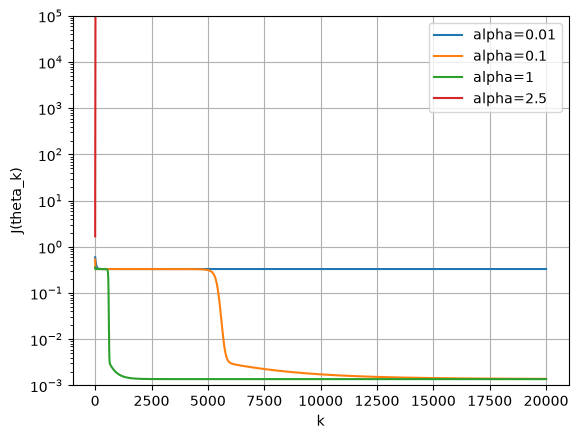

In [25]:
plt.figure()
plt.plot(hist_J001, label="alpha=0.01")
plt.plot(hist_J01, label="alpha=0.1")
plt.plot(hist_J1, label="alpha=1")
plt.plot(hist_J25, label="alpha=2.5")
plt.yscale("log")
plt.ylim(10**-3, 10**5) # alpha 2.5 va al infinito
plt.xlabel("k")
plt.ylabel("J(theta_k)")
plt.legend()
plt.grid(True)
plt.show()

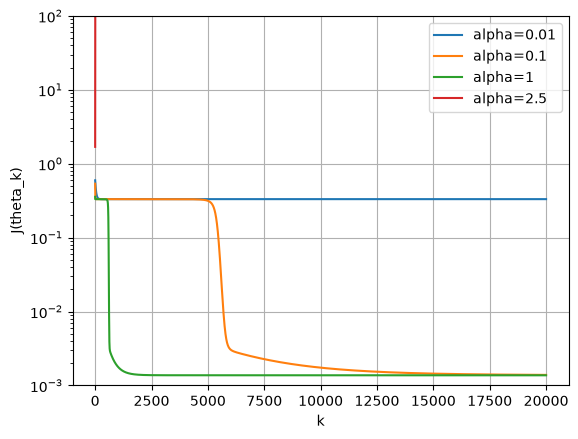

In [26]:
# para ver los descensos mejor
plt.figure()
plt.plot(hist_J001, label="alpha=0.01")
plt.plot(hist_J01, label="alpha=0.1")
plt.plot(hist_J1, label="alpha=1")
plt.plot(hist_J25, label="alpha=2.5")
plt.yscale("log")
plt.ylim(10**-3, 10**2) 
plt.xlabel("k")
plt.ylabel("J(theta_k)")
plt.legend()
plt.grid(True)
plt.show()

En conclusión, con un alpha muy pequeño el error casi no baja y con un alpha muy grande el error aumenta al infinito en vez de disminuir. El mejor alpha es 1, ya que desde la primera iteración el error es más pequeño que con los otros alphas y luego decrece de forma notoria hasta llegar al menor error

### Parte ii.
10 $\theta_0$ distintos con elementos al azar en [-1,1] y otros 10 en [-5,5]

Sabiendo por enunciado que $h_2=\sigma(z_2)$ y que $\sigma'(t)=\sigma(t)\big(1-\sigma(t)\big)$, entonces $\sigma'(z_2)=\sigma(z_2)\big(1-\sigma(z_2)\big)=h_2(1-h_2)$ siendo t = z2 

In [27]:
# dato inicial
np.random.seed(1)
J1 = np.zeros(10) # errores
for i in range(10):
    theta = np.random.uniform(-1, 1, 6)
    a1, b1, a2, b2, v, c = theta
    h2 = 1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2))) # capas x1
    oz2 = h2 * (1 - h2)
    for k in range(20000): # descenso del gradiente 
        theta = theta - 1 * grad_J(theta) # alpha 1
    J1[i] = J(theta) 
    t = a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2 # t = z2 al inicio
    print("J:", J(theta), "t:", t, "o'(z2):", oz2)

J: 0.001375300760668085 t: -1.0067002517394457 o'(z2): 0.19600237670478501
J: 0.0013752203865040088 t: -0.012266896056210036 o'(z2): 0.2499905954396838
J: 0.0013728430126290227 t: -0.3117552646163415 o'(z2): 0.24402260054539482
J: 0.0013751032935072041 t: 1.1569385801286722 o'(z2): 0.18199588099169337
J: 0.0013806764344265225 t: -1.4819679060491733 o'(z2): 0.15085711150671097
J: 0.0013739110030633562 t: 0.5025134962921745 o'(z2): 0.23485873931382648
J: 0.001376314979972549 t: -0.13052574521427895 o'(z2): 0.2489382056079392
J: 0.0013789322193034081 t: -0.6189175525438018 o'(z2): 0.22750830239809117
J: 0.0013742105600891893 t: 0.04013899112580677 o'(z2): 0.24989933087003838
J: 0.0013724668128321156 t: -0.6634499096658418 o'(z2): 0.22438881910847114


In [28]:
J5 = np.zeros(10)
for i in range(10):
    theta = np.random.uniform(-5, 5, 6)
    a1, b1, a2, b2, v, c = theta
    h2 = 1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2)))
    oz2 = h2 * (1 - h2)
    for k in range(20000):
        theta = theta - 1 * grad_J(theta) # alpha 1
    J5[i] = J(theta)
    t = a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2
    print("J:", J5[i], "t:", t, "o'(z2):", oz2)

J: 0.0013961601330082834 t: -0.14608752691114402 o'(z2): 0.24867088225086129
J: 0.0014059162299832819 t: 3.1114570822708263 o'(z2): 0.040819202976648664
J: 0.00140266675245887 t: -4.335219993233787 o'(z2): 0.012762451731096676
J: 0.3319273898461293 t: 4.637846929346351 o'(z2): 0.009493851663160916
J: 0.33189428766794693 t: 3.940593746191302 o'(z2): 0.018702573790602202
J: 0.0013837496061728416 t: 0.2871199018035551 o'(z2): 0.24491760879495422
J: 0.001362957798350016 t: -1.8297544332487545 o'(z2): 0.1191496199730467
J: 0.0014120280642364316 t: 1.8490601908348483 o'(z2): 0.11749182693020793
J: 0.0013995246035535549 t: -6.879114660348513 o'(z2): 0.001026940062439748
J: 0.0013903341928093995 t: 6.6359059939370315 o'(z2): 0.001308951228351146


In [29]:
print("promedio j1:", np.mean(J1), "promedio J5:", np.mean(J5))
print("j5 > J1:", np.mean(J5) > np.mean(J1))
print("j5/j1", np.mean(J5) / np.mean(J1))

print("mediana J1:", np.median(J1), "  mediana J5:", np.median(J5))
print("J5 > J1:", np.median(J5) > np.median(J1))
print("J5/j1", np.median(J5) / np.median(J1))

promedio j1: 0.0013754979462995461 promedio J5: 0.06749750148946489
j5 > J1: True
j5/j1 49.07132116849105
mediana J1: 0.0013751618400056065   mediana J5: 0.0014010956780062126
J5 > J1: True
J5/j1 1.0188587533817113


In [30]:
# 200 datos
np.random.seed(1)
J1 = np.zeros(10) # errores
for i in range(10):
    theta = np.random.uniform(-1, 1, 6)
    a1, b1, a2, b2, v, c = theta
    h2 = 1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x + b1)))) + b2))) # capas para todos los x
    oz2 = np.mean(h2 * (1 - h2)) 
    for k in range(20000):
        theta = theta - 1 * grad_J(theta) 
    J1[i] = J(theta)
    print("J:", J1[i], "promedio o'(z2):", oz2)

J: 0.001375300760668085 promedio o'(z2): 0.19629478335343076
J: 0.0013752203865040088 promedio o'(z2): 0.2499725857033337
J: 0.0013728430126290227 promedio o'(z2): 0.24424278925479825
J: 0.0013751032935072041 promedio o'(z2): 0.18237707013670193
J: 0.0013806764344265225 promedio o'(z2): 0.150492395007223
J: 0.0013739110030633562 promedio o'(z2): 0.23504039014683628
J: 0.001376314979972549 promedio o'(z2): 0.24872584019443222
J: 0.0013789322193034081 promedio o'(z2): 0.22795168106196553
J: 0.0013742105600891893 promedio o'(z2): 0.24970503817490022
J: 0.0013724668128321156 promedio o'(z2): 0.22438598318889053


In [31]:
J5 = np.zeros(10)
for i in range(10):
    theta = np.random.uniform(-5, 5, 6)
    a1, b1, a2, b2, v, c = theta
    h2 = 1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x + b1)))) + b2)))
    oz2 = np.mean(h2 * (1 - h2))
    for k in range(20000):
        theta = theta - 1 * grad_J(theta) # alpha 1
    J5[i] = J(theta)
    print("J:", J5[i], "promedio o'(z2):", oz2)

J: 0.0013961601330082834 promedio o'(z2): 0.22382764949226108
J: 0.0014059162299832819 promedio o'(z2): 0.04960971729883719
J: 0.00140266675245887 promedio o'(z2): 0.014457996213684845
J: 0.3319273898461293 promedio o'(z2): 0.014218431213269187
J: 0.33189428766794693 promedio o'(z2): 0.018418443273010406
J: 0.0013837496061728416 promedio o'(z2): 0.24389980057436303
J: 0.001362957798350016 promedio o'(z2): 0.12078208870482023
J: 0.0014120280642364316 promedio o'(z2): 0.09420384902770387
J: 0.0013995246035535549 promedio o'(z2): 0.0010409248300767152
J: 0.0013903341928093995 promedio o'(z2): 0.0027379501959684327


- J final no siempre es el mismo, $J1$ y $J5$ son diferentes e incluso dentro de cada rango las inicializaciones no repiten. El promedio de $J5$ es 49 veces el de $J1$, aunque sus medianas son casi iguales
- Recordando por (a) que $\sigma'(t)$ alcanza su máximo cerca de $t=0$ y se hace cada vez más chico con $t$ lejos de 0. En los resultados con $\theta_0$ en $[-5,5]$ los valores de $t=z_2$ tienden a quedar más lejos de 0 que en $[-1,1]$, por lo que $\sigma'(z_2)$ es más pequeño. Como el gradiente se multiplica por $\sigma'$, también queda muy pequeño y los parámetros cambian muy poco en $\theta-\alpha \nabla J(\theta)$
- El descenso del gradiente disminuye el error, pero no asegura el mínimo global, ya que no se llega a un único valor, sino que los J finales varían en un rango muy pequeño, como si cerca del mínimo J fuera una llanura plana porque el gradiente es casi 0

## Inciso G
### parte i.

Cargamos los pares $x_i,\tilde y_i$ del segundo archivo

In [32]:
df = pd.read_csv("datos/datos_P2_g.csv") # inciso c
x_g = df["x"].to_numpy() 
y_g = df["y"].to_numpy()
x = x_g # por dedf de j y grad
y = y_g

In [33]:
alpha = 1.0 # inciso d
max_iter = 20000
theta_g = theta0.copy()
hist_Jg = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta_g)
    theta_g = theta_g - alpha * g
    hist_Jg[k] = J(theta_g)

print("J(theta0) =", J(theta0))
print("J(theta20000) =", hist_Jg[-1])

J(theta0) = 0.4681636039845724
J(theta20000) = 0.07929184106945703


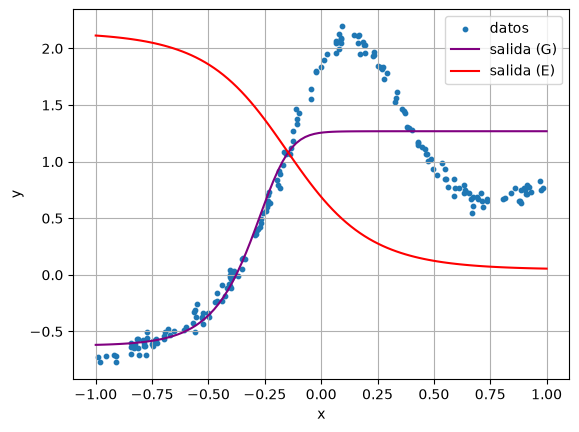

In [34]:
a1, b1, a2, b2, v, c = theta_g # entrenado
x_curvag = np.linspace(-1, 1, 100) # igual (e)
z1 = a1*x_curvag + b1 
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2
h2 = 1 / (1 + np.exp(-z2))
y_curvag = c + v*h2

plt.figure()
plt.scatter(x_g, y_g, s=10, label="datos")
plt.plot(x_curvag, y_curvag, color="purple", label="salida (G)")
plt.plot(xcurva, ycurva, color="red", label="salida (E)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

Notamos que al inicio tanto los datos como la curva suben, luego la curva se aplana mientras los datos siguen subiendo y dejan de coincidir. Después se vuelven a cruzar en un solo punto, pero los datos bajan y la curva sigue plana. Por eso la red no logra ajustar estos datos, solo se ajusta a una parte. Comparando con E, la curva de G sube y la de E baja, como una solo sube y la otra solo baja, se cruzan en un solo punto

### Parte ii.

La salida de la red es $\hat y=c+v\,h_2=c+v\,\sigma\big(a_2\,\sigma(a_1x+b_1)+b_2\big)$. Veremos el signo de su derivada si cumple con siempre subir o siempre bajar, con 15 $\theta$ al azar en $[-1,1]$. Para cada uno elegimos 10 $x$ al azar en $[-1,1]$ y calculamos la derivada por diferencias centradas

In [35]:
np.random.seed(2)
h = 10**-5 # igual que en a
for i in range(15):
    a1, b1, a2, b2, v, c = np.random.uniform(-1, 1, 6)
    x = np.random.uniform(-1, 1, 10)
    y1 = c + v /(1 + np.exp(-(a2 / (1 + np.exp(-(a1*(x + h) + b1))) + b2)))
    y2 = c + v /(1 + np.exp(-(a2 / (1 + np.exp(-(a1*(x - h) + b1))) + b2)))
    dy = (y1 - y2) / (2*h)
    y_gorro = c + v / (1 + np.exp(-(a2 /(1 + np.exp(-(a1*x + b1))) + b2)))
    print("a1*a2*v:", a1*a2*v, "dy:", np.round(dy, 5)) # monotona
    print("c:", round(c, 3), "c+v:", round(c + v, 3), "y gorro:", np.round(y_gorro, 3)) # cota
    print("entre c y c+v:", (y_gorro - c) * (y_gorro - (c + v)) < 0)

a1*a2*v: 0.0020249842061467824 dy: [0.0001  0.0001  0.0001  0.0001  0.0001  0.0001  0.00011 0.0001  0.00011
 0.0001 ]
c: -0.339 c+v: -0.499 y gorro: [-0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415]
entre c y c+v: [ True  True  True  True  True  True  True  True  True  True]
a1*a2*v: 0.0051484794046368874 dy: [0.0003  0.00027 0.00028 0.0003  0.00029 0.00027 0.00029 0.0003  0.0003
 0.00028]
c: -0.869 c+v: -0.859 y gorro: [-0.865 -0.866 -0.866 -0.865 -0.866 -0.866 -0.866 -0.866 -0.865 -0.866]
entre c y c+v: [ True  True  True  True  True  True  True  True  True  True]
a1*a2*v: 0.001727224153758903 dy: [0.00011 0.00011 0.00011 0.00011 0.00011 0.00011 0.00011 0.00011 0.00011
 0.00011]
c: 0.16 c+v: 0.747 y gorro: [0.421 0.421 0.421 0.421 0.421 0.421 0.421 0.421 0.421 0.421]
entre c y c+v: [ True  True  True  True  True  True  True  True  True  True]
a1*a2*v: -0.0016830111360012772 dy: [-7.e-05 -8.e-05 -8.e-05 -8.e-05 -7.e-05 -7.e-05 -7.e-05 -7.e-05 -7.e-05
 -8.e-05]
c:

In [36]:
x_sort = np.sort(x)
y_sort = c + v * (1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x_sort + b1)))) + b2))))
print("x ordenados:", np.round(x_sort, 3))
print("y gorro:", np.round(y_sort, 3))

x ordenados: [-0.543 -0.339 -0.226 -0.171  0.253  0.285  0.426  0.54   0.71   0.874]
y gorro: [0.707 0.708 0.708 0.709 0.71  0.711 0.711 0.711 0.712 0.713]


Notamos que en cada fila el signo de $a_1a_2v$ y el de todas las derivadas dy es el mismo, por lo que para cada $\theta$ la salida siempre crece o siempre decrece. Ademas como ejemplo, para el último $\theta$ ordenamos los $x$ y los $\hat y$ fueron aumentando en una sola dirección, es monótona. Para las cotas, notamos que todos los $\hat y$ están entre $c$ y $c+v$, al restarle cada uno, una resta da positiva y la otra negativa, por lo que su producto es negativo. Así se cumple $c<\hat y<c+v$ si $v>0$, y $c+v<\hat y<c$ si $v<0$